# Analisis exploratorio de datos de datos

En este notebook se realizara un analisis inicial de las variables del dataset que se genero para obtener las caracteristicas del dataset generado para obtener las caracteristicas por persona y su ingreso de los resultados de la ENIGH 2024

In [12]:
# Importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [18]:
# Traer datos

personas = pd.read_csv(r'/run/media/oswal/01DD260F5154F4B0/Duend/Documentos/1 IA y ciencia de datos/Semestre 3/proyecto integrador/Clean data/clean_data.csv')
print(personas.columns)
personas.head()

Index(['folioviv', 'foliohog', 'numren', 'edad', 'disc_ver', 'disc_oir',
       'disc_brazo', 'disc_camin', 'disc_apren', 'disc_vest', 'disc_habla',
       'disc_acti', 'nivelaprob', 'id_per', 'ing_tri_total', 'num_ingresos',
       'htrab_total', 'num_trabajos', 'sexo_H'],
      dtype='str')


,folioviv,foliohog,numren,edad,disc_ver,disc_oir,disc_brazo,disc_camin,disc_apren,disc_vest,disc_habla,disc_acti,nivelaprob,id_per,ing_tri_total,num_ingresos,htrab_total,num_trabajos,sexo_H
0,100001901,1,2,24.0,0,0,0,0,0,0,0,0,4.0,100001901102,31157.59,3.0,45.0,1.0,0
1,100001902,1,1,48.0,0,0,0,0,0,0,0,0,7.0,100001902101,56739.12,3.0,48.0,1.0,1
2,100001902,1,2,48.0,1,0,0,0,0,0,0,0,3.0,100001902102,0.00,0.0,0.0,0.0,0
3,100001902,1,3,22.0,0,0,0,0,0,0,0,0,7.0,100001902103,29347.82,1.0,48.0,1.0,1
4,100001902,1,4,16.0,0,0,0,0,0,0,0,0,4.0,100001902104,0.00,0.0,0.0,0.0,0


### Iniciar con el analisis de variables

In [24]:
print(personas.shape)

personas.notnull().sum()


(241427, 19)


folioviv         241427
foliohog         241427
numren           241427
edad             241427
disc_ver         241427
disc_oir         241427
disc_brazo       241427
disc_camin       241427
disc_apren       241427
disc_vest        241427
disc_habla       241427
disc_acti        241427
nivelaprob       241425
id_per           241427
ing_tri_total    241427
num_ingresos     241427
htrab_total      241427
num_trabajos     241427
sexo_H           241427
dtype: int64

In [14]:
# Analisis de ingresos

""" 
Los ingresos son nuestra variable objetivo.
Anteriormente ya se habia hecho una eliminaciond de datos atipicos, mediante un IQR, tomando como base esta variable.
"""

personas['ing_tri_total'].describe()

count    241427.000000
mean      17349.813005
std       17925.872046
min           0.000000
25%         245.900000
50%       12362.610000
75%       28266.870000
max       75937.490000
Name: ing_tri_total, dtype: float64

In [15]:
# Buscar normalidad de ingresos

# Aplicar prueba de Shapiro-Wilk
estadistico, p_valor = stats.shapiro(personas['ing_tri_total'])

print(f"Estadístico W: {estadistico:.4f}")
print(f"P-valor: {p_valor:.4f}")

if p_valor > 0.05:
    print("Los datos parecen seguir una distribución normal (no se rechaza H0)")
else:
    print("Los datos no siguen una distribución normal (se rechaza H0)")

Estadístico W: 0.8720
P-valor: 0.0000
Los datos no siguen una distribución normal (se rechaza H0)


/run/media/oswal/01DD260F5154F4B0/Duend/Documentos/1 IA y ciencia de datos/Semestre 3/proyecto integrador/.venv/lib64/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 241427.
  res = hypotest_fun_out(*samples, **kwds)


Text(0.5, 1.0, 'distribucion de ingresos')

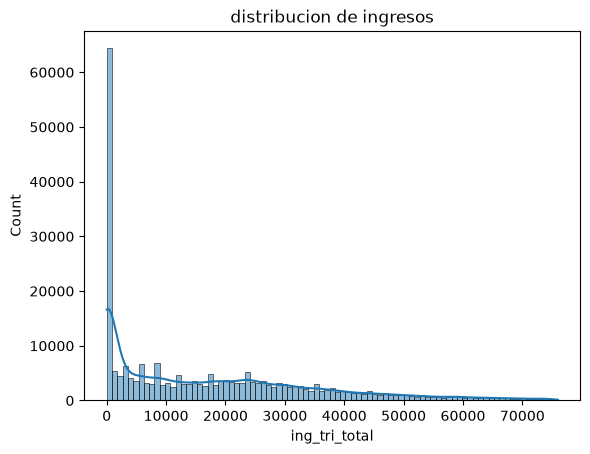

In [21]:
sns.histplot(personas['ing_tri_total'],kde=True).set_title('distribucion de ingresos')

Text(0.5, 1.0, 'distribucion de ingresos')

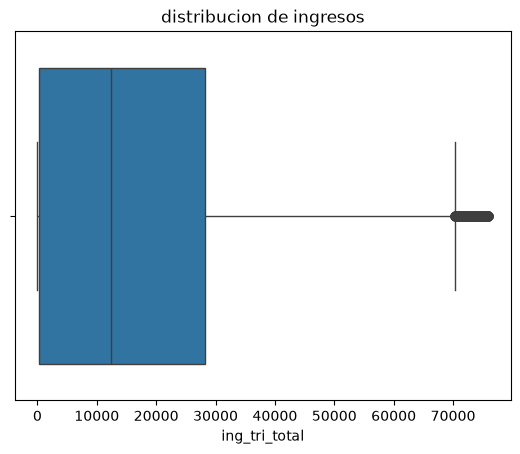

In [20]:
sns.boxplot(x=personas['ing_tri_total']).set_title('distribucion de ingresos')

# Edades


In [19]:
personas['edad'].describe()

count    241427.000000
mean         39.730954
std          19.305488
min          12.000000
25%          23.000000
50%          38.000000
75%          54.000000
max         106.000000
Name: edad, dtype: float64

Text(0.5, 1.0, 'distribucion de edades')

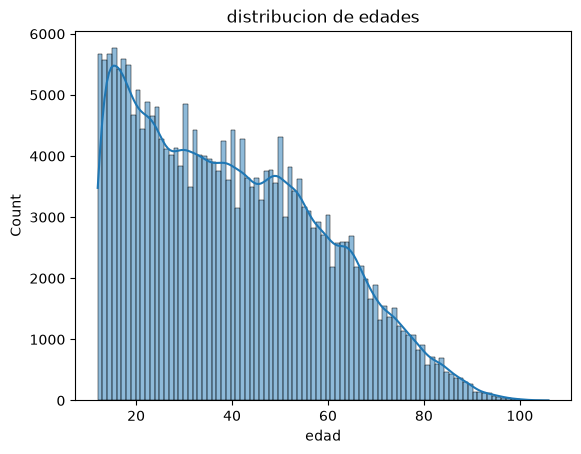

In [25]:
sns.histplot(personas['edad'],kde=True).set_title('distribucion de edades')

Text(0.5, 1.0, 'distribucion de edades')

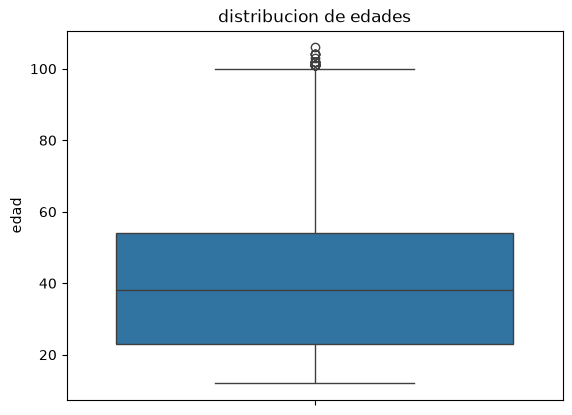

In [26]:
sns.boxplot(personas['edad']).set_title('distribucion de edades')

<Axes: title={'center': 'Nivel de estudios'}, xlabel='Nivel de estudios', ylabel='Cantidad de personas'>

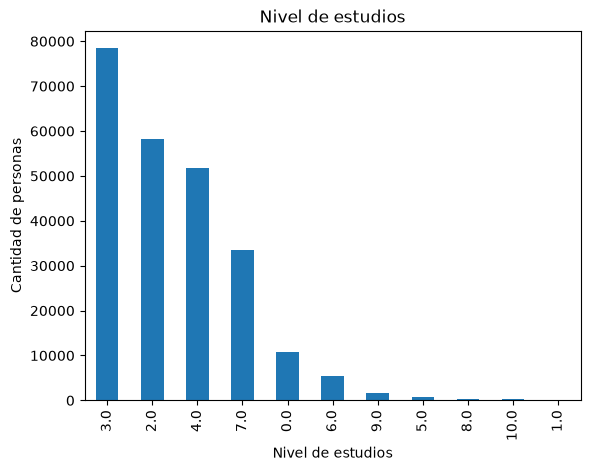

In [27]:
# Nivel de estudios
personas['nivelaprob'].value_counts().plot(kind='bar', title='Nivel de estudios', xlabel='Nivel de estudios', ylabel='Cantidad de personas')

In [28]:
personas['nivelaprob'].describe()

count    241425.000000
mean          3.522953
std           1.832642
min           0.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          10.000000
Name: nivelaprob, dtype: float64

# Pausa y notas.

Se han detectado situaciones quemuestrasn que el enfoque por persona podria no ser el correcto.

por lo que se procederá a hacer un analisis de las variables por hogar para evaluar si ese enfoque es mas adecuado